Written by: Trisha Jha

Last update: Aug, 2026

# CroP-LDM Tutorial

## Overview
CroP-LDM (cross-population prioritized linear dynamical model) is a method for linear dynamical modeling of interactions between two simultaneously recorded neural populations. Given the activity of a source population Y and a target population Z, CroP-LDM learns a dynamical model of population Y while prioritizing the dynamics that are shared with population Z.

For more details, see our manuscript: Jha T, Sani O G, Pesaran B and Shanechi M M 2025 Prioritized learning of cross-population neural dynamics *J. Neural Eng.* 22 046040.

CroP-LDM's implementation is derived from the [PSID](https://github.com/ShanechiLab/PyPSID) codebase (Sani, Abbaspourazad, Wong, Pesaran, and Shanechi, *Nature Neuroscience*, 2021).

## Model
Given the activity of a source population, $y_k$, and a target population, $z_k$, CroP-LDM learns a latent state $x_k$, composed of two components: $x_k^{(1)}$, the dynamics shared between populations Y and Z, and $x_k^{(2)}$, the within-population Y dynamics not shared with population Z. The model is formulated as:

$$ x_{k+1} = A x_k + w_k $$

$$ y_k = C_y x_k + v_k $$

$$ z_k = C_z x_k + \epsilon_k $$


*Note: in the CroP-LDM paper these two populations are referred to as population A and population B; here we call them population Y and population Z to match the naming used in the code below.*

# Using CroP-LDM
## Modeling data
To use CroP-LDM, import the model class:
```python
from CroPLDM import CroPLDMModel
```

You can then use it to model cross-population data as:
```python
idSys = CroPLDMModel(nx=2, n1=2, i=10)
idSys.fit(yTrain, zTrain)
```

With the following arguments:
- `yTrain`: Source population Y activity. Dimensions are: time x data dimension.
- `zTrain`: Target population Z activity, i.e. the cross-population prediction objective. Dimensions are: time x data dimension.
- `nx`: the total dimension of the latent state in the model.
- `n1`: the number of latent state dimensions dedicated to shared cross-population dynamics ($x_k^{(1)}$).
- `i`: the subspace horizon


After running the above, the learned model is stored in the object `idSys`.

## Using the model for cross-population prediction and self-prediction
For a learned model `idSys`, use `predict` to extract the latent state and predict both populations' activity given new source population Y activity:
```python
zPred, yPred, xPred = idSys.predict(yTest)
```
With the argument:
- `yTest`: Source population Y activity in the test data. Dimensions are: time x data dimension.

And with outputs (all dimensions are time x data dimension):
- `zPred`: Prediction of target population Z activity from past source population Y activity (i.e., cross-population prediction).
- `yPred`: Self-prediction of source population Y activity from its own past.
- `xPred`: The latent state extracted at each time point.

Note that inference only requires source population Y activity, consistent with CroP-LDM's design for settings where only one population is accessible at inference time.

We next go through a complete worked example on simulated data.

# Example: CroP-LDM on simulated cross-population data
In this example, we use CroP-LDM to model simulated data from a system with a known ground-truth model, and evaluate cross-population prediction performance against that ground truth.

First, we import CroP-LDM and a few other useful tools.

In [1]:
# CroP-LDM was tested with Python 3.11 (see the repository README for setup).
# This prints your Python version as a quick check.
!python --version

Python 3.11.15


In [2]:
import os
import pickle
import sys

sys.path.insert(0, os.path.join("..", ".."))
sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath("")), "..", ".."))

import numpy as np
import matplotlib.pyplot as plt

import CroPLDM
from CroPLDM import CroPLDMModel
from CroPLDM.evaluation import evalPrediction
from CroPLDM.LSSM import LSSM

Let's load the example data. It was simulated from a ground-truth linear model of two neural populations, each with 3 channels. The model has:

- 2 dimensions that are **shared** between the two populations
- 2 dimensions that are within population Y
- 2 dimensions that are within population Z


In [3]:
# Load data
data_dir = os.path.normpath(os.path.join(os.path.dirname(CroPLDM.__file__), "..", "..", "data"))
fName = "sample_data.p"

sample_data_path = os.path.join(data_dir, fName)

print("Loading example data from {}".format(sample_data_path))
with open(sample_data_path, "rb") as f:
    data = pickle.load(f)

y = data["y"]  # Source population Y activity
z = data["z"]  # Target population Z activity

trueSys = LSSM(params=data["trueSys"])  # The ground-truth model of population Y

n1 = data["n1"]  # Latent state dimensions shared between the two populations
nx = n1

allYData, allZData = y, z
print("Source population Y activity: {} samples x {} channels".format(*allYData.shape))
print("Target population Z activity: {} samples x {} channels".format(*allZData.shape))


Loading example data from /Users/trishajani/Documents/PhD/Research/Projects/CroPLDM/data/sample_data.p
Source population Y activity: 20000 samples x 3 channels
Target population Z activity: 20000 samples x 3 channels


Let's separate the data into training and test segments.

In [4]:
# Separate data into training and test data:
trainInds = np.arange(np.round(0.5 * allYData.shape[0]), dtype=int)
testInds = np.arange(1 + trainInds[-1], allYData.shape[0])
yTrain = allYData[trainInds, :]
yTest = allYData[testInds, :]
zTrain = allZData[trainInds, :]
zTest = allZData[testInds, :]

print("Training on {} samples, testing on {} samples".format(yTrain.shape[0], yTest.shape[0]))

Training on 10000 samples, testing on 10000 samples


## Section 1: Learning the shared dynamics with CroP-LDM

We fit CroP-LDM with $n_x = n_1 = 2$. Setting $n_1 = n_x$ means every latent state dimension is dedicated to the dynamics shared between the two populations. This is the setting to use when the goal is cross-population prediction rather than a complete description of population Y.

In [5]:
# Fit CroP-LDM to the training data:
# nx and n1 were set above from the ground-truth model (nx = n1 = 2)
i = 10  # Subspace horizon

idSys = CroPLDMModel(nx=nx, n1=n1, i=i)
idSys.fit(yTrain, zTrain)

print("Learned a CroP-LDM model with a {}D latent state".format(idSys.getLSSM().state_dim))

Learned a CroP-LDM model with a 2D latent state


Inference on test data and computing cross-population prediction performance:

In [6]:
# Inference:
print("Computing predictions for the learned model")
zTestPred, yTestPred, xTestPred = idSys.predict(yTest)

# Compute R2 of cross-population prediction (z from y)
zR2 = evalPrediction(zTest, zTestPred, "R2")

print("Cross-population prediction R2: {:.3f}".format(np.mean(zR2)))


Computing predictions for the learned model
Cross-population prediction R2: 0.600


For comparison, we can compute the cross-population prediction performance of the *true* model

In [7]:
# Ideal cross-population prediction, using the true model
zTestPredIdeal, _, _ = trueSys.predict(yTest)
zR2Ideal = evalPrediction(zTest, zTestPredIdeal, "R2")

print(
    "Cross-population prediction R2:\n  CroP-LDM => {:.3f}, Ideal using true model => {:.3f}".format(
        np.mean(zR2), np.mean(zR2Ideal)
    )
)


Cross-population prediction R2:
  CroP-LDM => 0.600, Ideal using true model => 0.623


## Section 2: Comparing true and identified dynamics

Next, we can plot the eigenvalues of the $A$ matrix from the learned model and compare with the eigenvalues of the $A$ matrix in the true model to see if CroP-LDM was able to identify the shared cross-population dynamics.

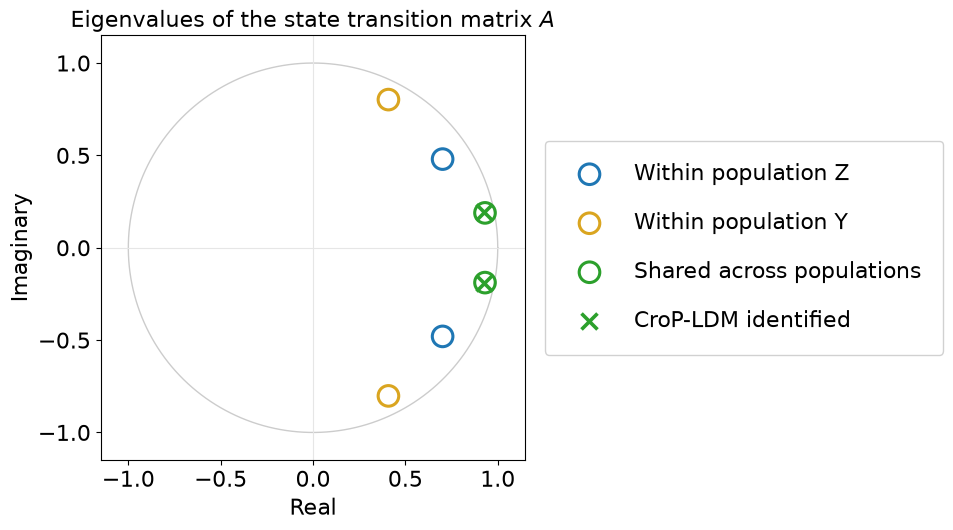

In [8]:
# True eigenvalues, split by whether the corresponding mode is read out to population Z
trueEigVals, trueEigVecs = np.linalg.eig(trueSys.A)
CzInEigenBasis = np.abs(trueSys.Cz @ trueEigVecs).sum(axis=0)

isShared = CzInEigenBasis > 1e-10
trueEigShared = trueEigVals[isShared]
trueEigNotShared = trueEigVals[~isShared]

# Modes that drive population Z only, and are not represented in population Y at all
trueEigZOnly = np.linalg.eigvals(data["epsSys"]["A"])

# Eigenvalues identified by CroP-LDM
idEigVals = np.linalg.eigvals(idSys.getLSSM().A)

# Plot true vs. identified eigenvalues in the complex plane
fig, ax = plt.subplots(figsize=(8.4, 5.4))

fontSize = 16
markerSize = 220

# Unit circle marks the stability boundary
theta = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), color="0.8", lw=1, zorder=0)
ax.axhline(0, color="0.9", lw=0.8, zorder=0)
ax.axvline(0, color="0.9", lw=0.8, zorder=0)

sharedColor = "tab:green"

ax.scatter(
    trueEigZOnly.real, trueEigZOnly.imag,
    s=markerSize, facecolors="none", edgecolors="tab:blue", lw=2.2,
    label="Within population Z", zorder=2,
)
ax.scatter(
    trueEigNotShared.real, trueEigNotShared.imag,
    s=markerSize, facecolors="none", edgecolors="goldenrod", lw=2.2,
    label="Within population Y", zorder=3,
)
ax.scatter(
    trueEigShared.real, trueEigShared.imag,
    s=markerSize, facecolors="none", edgecolors=sharedColor, lw=2.2,
    label="Shared across populations", zorder=4,
)
ax.scatter(
    idEigVals.real, idEigVals.imag,
    s=markerSize * 0.6, color=sharedColor, marker="x", lw=2.6,
    label="CroP-LDM identified", zorder=5,
)

ax.set_xlabel("Real", fontsize=fontSize)
ax.set_ylabel("Imaginary", fontsize=fontSize)
ax.set_title("Eigenvalues of the state transition matrix $A$", fontsize=fontSize)
ax.tick_params(axis="both", labelsize=fontSize)
ax.set_aspect("equal")
ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=fontSize,
    framealpha=0.9,
    labelspacing=1.2,
    handletextpad=1.0,
    borderpad=1.0,
)
plt.tight_layout()
plt.show()


## Section 3: Causal prediction vs. filtering and smoothing

So far, inference has been *causal* in time: the prediction of $z_k$ uses only source population Y activity up to time $k-1$. CroP-LDM also supports two other inference modes:

- `'filtering'`, which estimates $z_k$ using population Y activity up to and including time $k$;
- `'smoothing'`, which estimates $z_k$ using the entire population Y recording, both past **and future**.

Smoothing is no longer causal in time, as it requires the full population Y activity, but it can improve prediction accuracy. The inference mode is set with the `default_inference` argument when the model is constructed, or changed after fitting with `set_default_inference`.

In [9]:
# A fitted model can switch inference mode without refitting
idSysF = CroPLDMModel(nx=nx, n1=n1, i=i, default_inference="prediction")
idSysF.fit(yTrain, zTrain)

zTestPredF, _, _ = idSysF.predict(yTest)

idSysF.set_default_inference("filtering")
zTestFilt, _, _ = idSysF.predict(yTest)

idSysF.set_default_inference("smoothing")
zTestSmth, _, _ = idSysF.predict(yTest)

zR2Pred = evalPrediction(zTest, zTestPredF, "R2")
zR2Filt = evalPrediction(zTest, zTestFilt, "R2")
zR2Smth = evalPrediction(zTest, zTestSmth, "R2")

# The same, using the true model as a baseline
zTestFiltIdeal, _, _ = trueSys.predict(yTest, useXFilt=True)
zTestSmthIdeal, _, _ = trueSys.predict(yTest, useXSmooth=True)

zR2FiltIdeal = evalPrediction(zTest, zTestFiltIdeal, "R2")
zR2SmthIdeal = evalPrediction(zTest, zTestSmthIdeal, "R2")

print(
    "Cross-population prediction R2 using CroP-LDM:\n"
    "  Prediction => {:.3f}, Filtering => {:.3f}, Smoothing => {:.3f}".format(
        np.mean(zR2Pred), np.mean(zR2Filt), np.mean(zR2Smth)
    )
)
print(
    "Cross-population prediction R2 using true model (ideal):\n"
    "  Prediction => {:.3f}, Filtering => {:.3f}, Smoothing => {:.3f}".format(
        np.mean(zR2Ideal), np.mean(zR2FiltIdeal), np.mean(zR2SmthIdeal)
    )
)

Cross-population prediction R2 using CroP-LDM:
  Prediction => 0.600, Filtering => 0.675, Smoothing => 0.714
Cross-population prediction R2 using true model (ideal):
  Prediction => 0.623, Filtering => 0.701, Smoothing => 0.748


# How to pick the state dimensions `nx` and `n1`?

The right values depend on the goal of the modeling. For dimension reduction, `nx` is the target dimension, and setting `n1 = nx` preserves as much of the shared cross-population dynamics as possible. For the best overall fit to data, pick `nx` and `n1` by a grid search, selecting the pair with the best cross-population prediction in an inner cross-validation within the training data.

The horizon `i` must be at least 2, and bounds the dimensions that can be learned (`n1 <= nz * i`, `nx <= ny * i`), so choose a larger `i` for low-dimensional populations. It can be selected by inner cross-validation as well.

# Licence

Copyright © 2025 The University of Southern California. All Rights Reserved. See the `LICENSE` file in the CroP-LDM directory for the terms of use.